# **DL Unit Test - 2**

# **2) Household Electricity Consumption**

Importing Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
import math

**TASK 1: Load, handle missing, and normalize**

Loading Dataset and Replacing '?' with Nan

In [4]:
df = pd.read_csv('household_power_consumption.txt', sep=';',
                 parse_dates={'datetime': ['Date', 'Time']},
                 infer_datetime_format=True,
                 na_values=['?'], index_col='datetime')

/tmp/ipykernel_918/2199226122.py:1: FutureWarning: Support for nested sequences for 'parse_dates' in pd.read_csv is deprecated. Combine the desired columns with pd.to_datetime after parsing instead.
  df = pd.read_csv('household_power_consumption.txt', sep=';',
/tmp/ipykernel_918/2199226122.py:1: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  df = pd.read_csv('household_power_consumption.txt', sep=';',
/tmp/ipykernel_918/2199226122.py:1: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df = pd.read_csv('household_power_consumption.txt', sep=';',


Select the target variable for consumption forecasting

In [5]:
data = df[['Global_active_power']].copy()

Handle missing values using forward fill (carries the last valid observation forward)

In [6]:
data = data.ffill()

Select 10,000 consecutive valid minute-level records

In [7]:
data_subset = data.iloc[:10000].values

Normalize the numerical features (Scale between 0 and 1)

In [8]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data_subset)

**TASK 2: Generate sequences**

In [9]:
def create_sequences(dataset, sequence_length):
    X, y = [], []
    # Slide the window across the data
    for i in range(sequence_length, len(dataset)):
        X.append(dataset[i-sequence_length:i, 0]) # Past 'sequence_length' minutes
        y.append(dataset[i, 0])                   # Next minute to predict
    return np.array(X), np.array(y)

Use 60 minutes of historical data to predict the next minute

In [10]:
seq_length = 60
X, y = create_sequences(scaled_data, seq_length)

Reshape X to fit LSTM input requirement: [samples, time steps, features]

In [11]:
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

Split into training (80%) and testing (20%) sets

In [12]:
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

**TASK 3: Select, justify, and train the model**

***Justification: LSTM is chosen because it inherently handles sequential data and mitigates the vanishing gradient problem in long time-series.***

In [13]:
print("Building and training LSTM model...")
model = Sequential()
model.add(LSTM(50, return_sequences=False, input_shape=(X_train.shape[1], 1)))
model.add(Dense(1))

Building and training LSTM model...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Compile the model

In [14]:
model.compile(optimizer='adam', loss='mean_squared_error')

Train the model

In [29]:
history = model.fit(X_train,
                    y_train,
                    batch_size=32,
                    epochs=10,
                    validation_split=0.1,
                    verbose=1)

Epoch 1/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0025 - val_loss: 7.4565e-04
Epoch 2/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0025 - val_loss: 7.2253e-04
Epoch 3/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0024 - val_loss: 7.7233e-04
Epoch 4/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0024 - val_loss: 8.0108e-04
Epoch 5/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0024 - val_loss: 8.8677e-04
Epoch 6/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0023 - val_loss: 6.6924e-04
Epoch 7/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0023 - val_loss: 7.2782e-04
Epoch 8/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0023 - val_loss: 6.9593e-04
Epoch 9/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0022 - val_loss: 6.7431e-04
Epoch 10/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0022 - val_loss: 7.3064e-04


**TASK 4: Calculate MAE and RMSE**

Generate predictions on the unseen test data

In [30]:
predictions = model.predict(X_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


Inverse transform predictions and actuals back to original kW scale

In [31]:
predictions_inv = scaler.inverse_transform(predictions)
y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))

Calculate metrics

In [32]:
mae = mean_absolute_error(y_test_inv, predictions_inv)
rmse = math.sqrt(mean_squared_error(y_test_inv, predictions_inv))

print("-" * 30)
print(f"Mean Absolute Error (MAE): {mae:.4f} kW")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} kW")
print("-" * 30)

------------------------------
Mean Absolute Error (MAE): 0.3799 kW
Root Mean Squared Error (RMSE): 0.5844 kW
------------------------------


**TASK 5: Visualize actual vs predicted**

In [34]:
plt.figure(figsize=(14, 6))

<Figure size 1400x600 with 0 Axes>

<Figure size 1400x600 with 0 Axes>

Plotting only the first 300 test records for visual clarity

In [35]:
visual_limit = 300

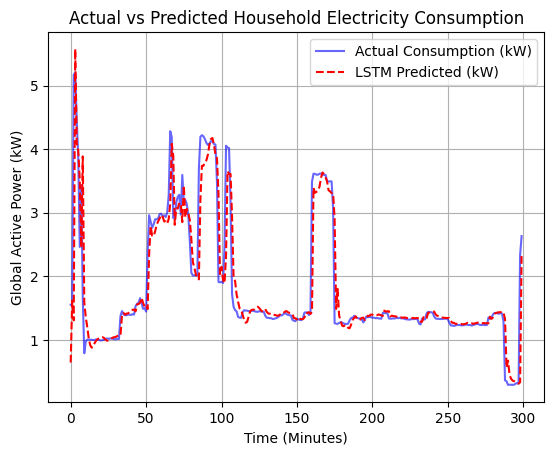

In [36]:
plt.plot(y_test_inv[:visual_limit], color='blue', label='Actual Consumption (kW)', alpha=0.6)
plt.plot(predictions_inv[:visual_limit], color='red', label='LSTM Predicted (kW)', linestyle='dashed')
plt.title('Actual vs Predicted Household Electricity Consumption')
plt.xlabel('Time (Minutes)')
plt.ylabel('Global Active Power (kW)')
plt.legend()
plt.grid(True)
plt.show()

Save Model file

In [37]:
model.save('electricity_lstm_model.keras')
print("Model saved successfully!")

Model saved successfully!
